In [5]:
import pandas as pd
import numpy as np
# veriyi oku
df = pd.read_csv('hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [6]:
import zipfile 
# zip dosyasını çıkart
with zipfile.ZipFile('hotel_bookings.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

In [9]:
# veri seti boyutu
print(f"Toplam Satır: {df.shape[0]}, Sütun: {df.shape[1]}\n")

# eksik değer kontrolü
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values >0]
print("--- Eksik Veri İçeren Sütunlar ---")
print(missing_values)

Toplam Satır: 119390, Sütun: 32

--- Eksik Veri İçeren Sütunlar ---
children         4
country        488
agent        16340
company     112593
dtype: int64


In [13]:
# eksik değerleri doldurma
df['agent'] = df['agent'].fillna(0)
df['children'] = df['children'].fillna(0)
df['company'] = df['company'].fillna(0)
df['country'] = df['country'].fillna('Unknown')

# eksik değer kaldı mı komtrol edelim
print("Kalan eksik değer sayısı:", df.isnull().sum().sum())

Kalan eksik değer sayısı: 0


In [14]:
# toplam misafir sayısı 0 olanlardan kurtulma
zero_guests = (df['adults'] + df['children'] + df['babies']) ==0
print(f"Temizlenecek hatalı satır sayısı: {zero_guests.sum()}")

df = df[~zero_guests]
print(f"Temizleme sonrası kalan toplam satır: {len(df)}")

Temizlenecek hatalı satır sayısı: 180
Temizleme sonrası kalan toplam satır: 119210


In [18]:
# işimize yarayacak yeni metrikler

# 1. toplam konaklanan gece sayısı
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# 2. toplam misafir sayısı
df['total_guests'] = df['adults'] + df['children'] + df['babies']

# 3. aile durumu (çocuklu 1, değilse 0)
df['is_family'] = np.where((df['children'] > 0) | (df['babies'] > 0), 1 , 0)

# yeni oluşturduğumuz sütunların kontrolü
df[['total_stay', 'total_guests', 'is_family']].head()

,total_stay,total_guests,is_family
0,0,2.0,0
1,0,2.0,0
2,1,1.0,0
3,1,1.0,0
4,2,2.0,0


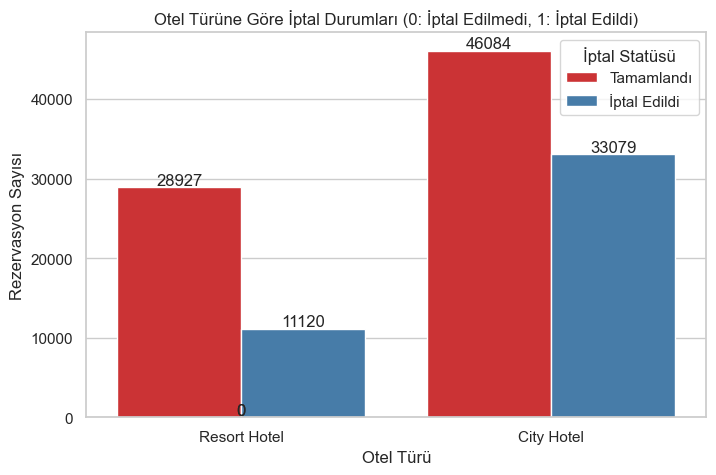

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# grafik stili
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# otel türüne göre iptal durumu
ax = sns.countplot(x='hotel', hue='is_canceled', data=df, palette='Set1')

plt.title('Otel Türüne Göre İptal Durumları (0: İptal Edilmedi, 1: İptal Edildi)')
plt.xlabel('Otel Türü')
plt.ylabel('Rezervasyon Sayısı')
plt.legend(title='İptal Statüsü', labels=['Tamamlandı', 'İptal Edildi'])

# yüzde veya sayı ekleme
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
               ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

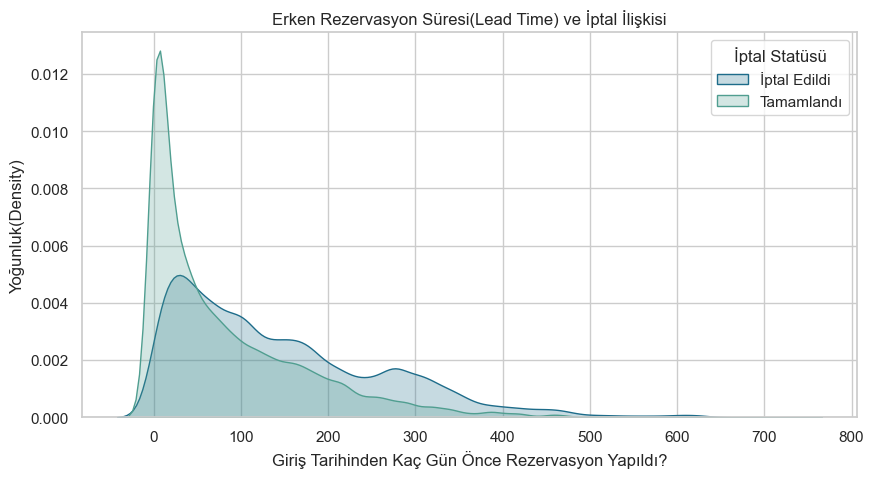

In [27]:
plt.figure(figsize=(10, 5))

# erken rezervasyon gün dağılımı (KDE Plot)
sns.kdeplot(data=df, x='lead_time', hue='is_canceled', common_norm=False, palette='crest', fill=True)

plt.title('Erken Rezervasyon Süresi(Lead Time) ve İptal İlişkisi')
plt.xlabel('Giriş Tarihinden Kaç Gün Önce Rezervasyon Yapıldı?')
plt.ylabel('Yoğunluk(Density)')
plt.legend(title='İptal Statüsü', labels=['İptal Edildi', 'Tamamlandı'])

plt.show()

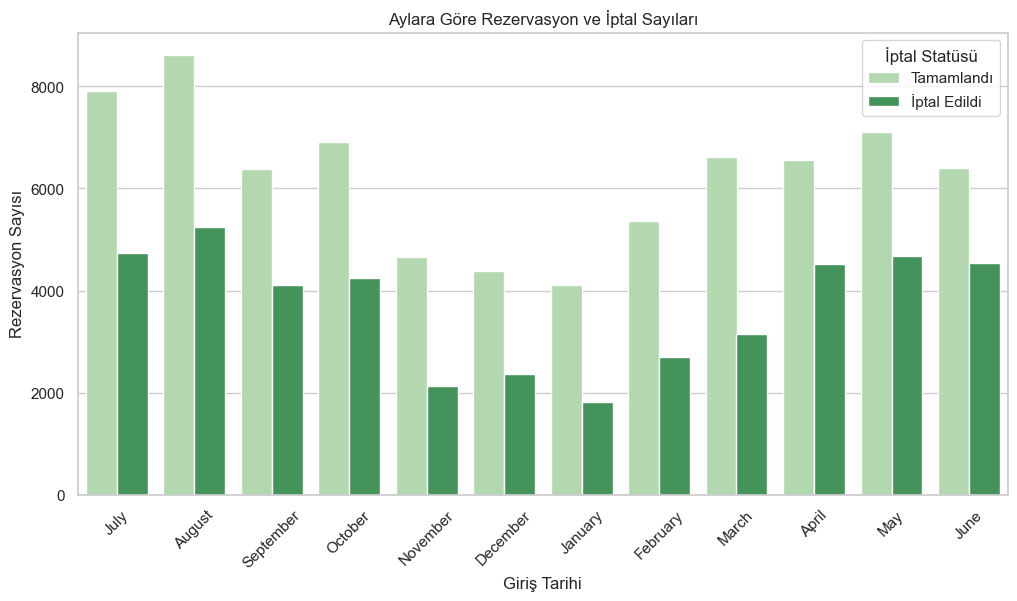

In [31]:
# ayları sıraya dizelim
months= ["January", "February", "March", "April", "May", "June", "July", "Agust", "September", "October", "November", "December"]

df['arrival_data_month'] = pd.Categorical(df['arrival_date_month'], categories=months, ordered=True)

plt.figure(figsize=(12, 6))
sns.countplot(x='arrival_date_month', hue='is_canceled', data=df, palette='Greens')

plt.title('Aylara Göre Rezervasyon ve İptal Sayıları')
plt.xlabel('Giriş Tarihi')
plt.ylabel('Rezervasyon Sayısı')
plt.xticks(rotation=45)
plt.legend(title='İptal Statüsü', labels=['Tamamlandı', 'İptal Edildi'])

plt.show()